In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

In [2]:
# Set up

# Parameters
alpha = 0.95
t = 0
dt = 1 / 252
T = 0.292

S0 = 152.51
K = 170
r = 0.00119
sigma = 0.4907
mu = 0.1691

N = 40000
J = 10
n_puts = 100

# Black-Scholes put price and delta
def bs_put(S, t):
    tau = T - t

    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * tau) / (
        sigma * np.sqrt(tau)
    )

    d2 = d1 - sigma * np.sqrt(tau)

    put_price = (
        K * np.exp(-r * tau) * norm.cdf(-d2)
        - S * norm.cdf(-d1)
    )

    put_delta = norm.cdf(d1) - 1

    return put_price, put_delta


# Initial portfolio
P0, h0 = bs_put(S0, t)

Y0 = -h0 * S0
V0 = Y0 + h0 * S0 - P0

print(f"Initial put price: {P0:.4f}")
print(f"Initial put delta: {h0:.4f}")
print(f"Initial money market balance: {Y0:.4f}")
print(f"Initial portfolio value per put: {V0:.4f}")

Initial put price: 27.1077
Initial put delta: -0.6086
Initial money market balance: 92.8107
Initial portfolio value per put: -27.1077


In [3]:
#One-day VaR and square-root-of-time rule

rng = np.random.default_rng(42)

# Generate shocks for 40,000 paths over 10 days
Z = rng.standard_normal((N, J))

# Simulate one-day stock prices
S1 = S0 * np.exp(
    (mu - 0.5 * sigma**2) * dt
    + sigma * np.sqrt(dt) * Z[:, 0]
)

# Reprice the put at the end of day 1
P1, _ = bs_put(S1, dt)

# Keep initial hedge unchanged during day 1
V1 = h0 * S1 + Y0 * np.exp(r * dt) - P1

# Portfolio loss for 100 puts
loss_1d = n_puts * (V0 - V1)

# One-day 95% VaR
var_1d = np.quantile(loss_1d, alpha)

# Square-root-of-time estimate
var_10d_sqrt = np.sqrt(J) * var_1d

print(f"One-day 95% VaR: USD {var_1d:.4f}")
print(f"10-day 95% VaR (sqrt rule): USD {var_10d_sqrt:.4f}")

One-day 95% VaR: USD 29.9280
10-day 95% VaR (sqrt rule): USD 94.6406


In [4]:
#Full 10-day Monte Carlo simulation

# Initialize all simulation paths
S = np.full(N, S0)
h = np.full(N, h0)
cash = np.full(N, Y0)

# Simulate 10 trading days
for j in range(J):

    # Simulate stock movement
    S = S * np.exp(
        (mu - 0.5 * sigma**2) * dt
        + sigma * np.sqrt(dt) * Z[:, j]
    )

    # Money market grows at risk-free rate
    cash = cash * np.exp(r * dt)

    # Recalculate put price and delta
    P, new_h = bs_put(S, (j + 1) * dt)

    # Rebalance hedge except at final day
    if j < J - 1:
        cash -= (new_h - h) * S
        h = new_h

# Final portfolio value
V10 = h * S + cash - P

# Calculate loss for 100 short puts
loss_10d = n_puts * (V0 - V10)

# Empirical 95% VaR
var_10d_sim = np.quantile(loss_10d, alpha)

print(f"Full 10-day 95% VaR: USD {var_10d_sim:.4f}")

Full 10-day 95% VaR: USD 89.2942


In [5]:
#Compare the estimates

comparison = pd.DataFrame({
    "Method": [
        "Square-root-of-time",
        "Full 10-day simulation"
    ],
    "95% VaR (USD)": [
        var_10d_sqrt,
        var_10d_sim
    ]
})

display(comparison)

difference = var_10d_sqrt - var_10d_sim
percentage = difference / var_10d_sim * 100

print(f"Absolute difference: USD {difference:.4f}")
print(f"Percentage difference: {percentage:.2f}%")

,Method,95% VaR (USD)
0,Square-root-of-time,94.640555
1,Full 10-day simulation,89.294191


Absolute difference: USD 5.3464
Percentage difference: 5.99%


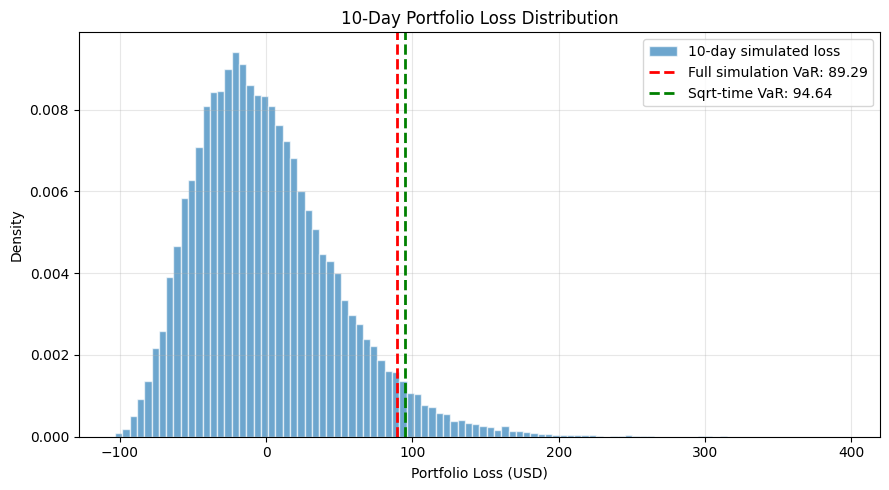

In [6]:
plt.figure(figsize=(9, 5))

plt.hist(
    loss_10d,
    bins=100,
    density=True,
    alpha=0.65,
    edgecolor="white",
    label="10-day simulated loss"
)

plt.axvline(
    var_10d_sim,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Full simulation VaR: {var_10d_sim:.2f}"
)

plt.axvline(
    var_10d_sqrt,
    color="green",
    linestyle="--",
    linewidth=2,
    label=f"Sqrt-time VaR: {var_10d_sqrt:.2f}"
)

plt.xlabel("Portfolio Loss (USD)")
plt.ylabel("Density")
plt.title("10-Day Portfolio Loss Distribution")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Comparison of the Two VaR Estimates

The square-root-of-time approach produces an estimated 10-day 95% VaR of approximately USD 94.64, while the full 10-day Monte Carlo simulation produces a VaR of approximately USD 89.29.

The square-root-of-time method gives a slightly higher risk estimate in this simulation.

The difference arises because the square-root-of-time rule assumes that portfolio losses scale approximately with the square root of the holding period. This approximation is most appropriate when daily losses are independent and identically distributed with constant variance and negligible drift.

However, our portfolio contains a short put option, which has nonlinear exposure to the underlying stock price because of its gamma and other option sensitivities. In addition, the delta hedge is dynamically rebalanced during the 10-day simulation.

The full Monte Carlo approach captures the changes in the stock price, option value, delta exposure, and money market balance throughout the 10-day period. Consequently, its simulated loss distribution differs from the simple time-scaled one-day distribution.

In this example, the square-root-of-time method overestimates VaR by approximately 5.99% relative to the full simulation. This difference is specific to the given parameters and simulation and does not imply that the square-root-of-time method always overestimates risk.

Overall, the full 10-day Monte Carlo simulation provides a more detailed representation of the risk associated with the dynamically delta-hedged short put position.